# Task 01 — Clean & Prepare a Dataset: Tokyo electricity demand × JMA temperature

**Question:** at which temperatures does the Tokyo area hit **peak** electricity demand, and at which is demand **lowest**?

**Data:** 39,744 hourly records (2022-04-01 → 2026-10-12, JST) that combine
* **TEPCO Power Grid "でんき予報"** area demand, supply capacity, and solar output (raw unit 万kW = 10 MW), and
* **Japan Meteorological Agency (気象庁)** hourly observations (temperature, humidity, sunshine) for Tokyo and 7 other Kanto stations.

The file was compiled from the official downloads by the open-source project
[kaseee/tokyo-grid-lab](https://github.com/kaseee/tokyo-grid-lab), which had already done some tidying. Each step below checks
the data honestly rather than assuming it is clean. Reusable code: `src/clean_prepare.py` and `src/analysis.py`.

In [1]:
import sys, json
from pathlib import Path
import pandas as pd
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 120)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import clean_prepare as cp
import analysis

## 1. Load the dataset

In [2]:
raw = cp.load_raw(ROOT / "data/raw/tokyo_hourly_demand_weather_raw.csv.gz")
print(f"Loaded {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

Loaded 39,744 rows x 34 columns


,datetime,demand,tepco_forecast,usage_rate,supply,demand_from_5min,solar,temp_tokyo,rh_tokyo,sun_tokyo,temp_yokohama,rh_yokohama,sun_yokohama,temp_chiba,rh_chiba,sun_chiba,temp_kumagaya,rh_kumagaya,sun_kumagaya,temp_mito,rh_mito,sun_mito,temp_utsunomiya,rh_utsunomiya,sun_utsunomiya,temp_maebashi,rh_maebashi,sun_maebashi,temp_kofu,rh_kofu,sun_kofu,temp_kanto,rh_kanto,sun_kanto
0,2022-04-01 00:00:00,2529.0,2488.0,81,3114,2528.250,0.0,8.60,95.0,0.0,9.65,93.0,0.0,9.10,87.0,0.0,9.05,95.0,0.0,5.75,87.5,0.0,7.30,96.5,0.0,8.15,76.5,0.0,10.40,74.0,0.0,8.736,91.846,0.0
1,2022-04-01 01:00:00,2443.0,2435.0,79,3088,2433.500,0.0,7.80,95.0,0.0,8.85,93.0,0.0,8.20,87.0,0.0,8.40,90.0,0.0,5.30,87.5,0.0,6.60,90.5,0.0,7.40,69.5,0.0,9.15,81.5,0.0,7.968,90.591,0.0
2,2022-04-01 02:00:00,2455.0,2435.0,79,3088,2443.833,0.0,6.95,95.0,0.0,7.95,93.5,0.0,7.35,86.0,0.0,7.20,83.5,0.0,4.95,86.5,0.0,5.85,83.5,0.0,6.35,66.5,0.0,7.80,86.0,0.0,7.068,89.062,0.0
3,2022-04-01 03:00:00,2507.0,2467.0,80,3121,2493.167,0.0,6.10,95.5,0.0,7.25,94.0,0.0,6.30,84.0,0.0,5.70,83.0,0.0,4.65,84.5,0.0,5.35,82.5,0.0,5.85,67.0,0.0,6.40,86.0,0.0,6.170,88.808,0.0
4,2022-04-01 04:00:00,2569.0,2528.0,82,3124,2556.417,0.0,5.40,95.0,0.0,6.30,92.0,0.0,5.35,83.5,0.0,4.80,84.0,0.0,4.30,84.5,0.0,4.75,86.0,0.0,5.85,69.0,0.0,5.25,87.5,0.0,5.398,88.596,0.0


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 39744 entries, 0 to 39743
Data columns (total 34 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   datetime          39744 non-null  str    
 1   demand            39744 non-null  float64
 2   tepco_forecast    39744 non-null  float64
 3   usage_rate        39744 non-null  int64  
 4   supply            39744 non-null  int64  
 5   demand_from_5min  39744 non-null  float64
 6   solar             39744 non-null  float64
 7   temp_tokyo        39744 non-null  float64
 8   rh_tokyo          39744 non-null  float64
 9   sun_tokyo         39744 non-null  float64
 10  temp_yokohama     39744 non-null  float64
 11  rh_yokohama       39744 non-null  float64
 12  sun_yokohama      39744 non-null  float64
 13  temp_chiba        39744 non-null  float64
 14  rh_chiba          39673 non-null  float64
 15  sun_chiba         39744 non-null  float64
 16  temp_kumagaya     39744 non-null  float64
 17  rh_k

## 2. Identify missing values
Check blank cells *and* missing hours: a gap in an hourly series is also missing data.

In [4]:
na = raw.isna().sum()
print("Blank cells per column:", na[na > 0].to_dict())
ts = pd.to_datetime(raw["datetime"])
full = pd.date_range(ts.min(), ts.max(), freq="h")
print(f"Expected hours: {len(full):,} | present: {ts.nunique():,} | missing hours: {len(full.difference(ts))}")
gaps = {c: int(cp._nan_runs(raw[c]).max()) for c in na[na > 0].index}
print("Longest gap per column (hours):", gaps)
raw.loc[raw.rh_chiba.isna(), "datetime"].str[:10].value_counts().sort_index()

Blank cells per column: {'rh_chiba': 71, 'rh_kumagaya': 32, 'rh_utsunomiya': 82, 'temp_maebashi': 2, 'rh_maebashi': 42}
Expected hours: 39,744 | present: 39,744 | missing hours: 0
Longest gap per column (hours): {'rh_chiba': 71, 'rh_kumagaya': 32, 'rh_utsunomiya': 82, 'temp_maebashi': 2, 'rh_maebashi': 40}


datetime
2022-09-19    19
2022-09-20    24
2022-09-21    24
2022-09-22     4
Name: count, dtype: int64

## 3. Duplicate records

In [5]:
print("Duplicate rows:      ", raw.duplicated().sum())
print("Duplicate timestamps:", raw["datetime"].duplicated().sum())

Duplicate rows:       0
Duplicate timestamps: 0


No duplicates in this file. The pipeline still checks for and removes them, so it stays safe if new months are appended later.

## 4. Incorrect / inconsistent values
Range checks against physical limits, consistency between related columns, and sudden jumps.

In [6]:
print(raw[["demand", "supply", "usage_rate", "solar", "temp_tokyo", "rh_tokyo", "sun_tokyo"]].describe().round(2).T[["min", "max", "mean"]])
calc = raw.demand / raw.supply * 100
print("\nusage_rate inconsistent with demand/supply:", int(((calc - raw.usage_rate).abs() > 1).sum()))
print("Demand above supply capacity:            ", int((raw.demand > raw.supply).sum()))
gap = (raw.demand - raw.demand_from_5min).abs() / raw.demand
print("Hourly demand vs 5-min average differ >3%:", int((gap > 0.03).sum()))
raw.loc[gap > 0.03, ["datetime", "demand", "demand_from_5min", "tepco_forecast"]]

                min      max     mean
demand      1853.00  5930.00  3171.12
supply      2114.00  6742.00  3855.61
usage_rate    57.00    99.00    81.91
solar          0.00  1776.42   286.28
temp_tokyo    -3.15    38.05    17.96
rh_tokyo      16.50   100.00    69.63
sun_tokyo      0.00     1.00     0.24

usage_rate inconsistent with demand/supply: 0
Demand above supply capacity:             0
Hourly demand vs 5-min average differ >3%: 8


,datetime,demand,demand_from_5min,tepco_forecast
24688,2025-01-23 16:00:00,3795.0,3642.000,3865.0
24689,2025-01-23 17:00:00,3944.0,3771.083,3942.0
24690,2025-01-23 18:00:00,3972.0,3811.167,3851.0
24691,2025-01-23 19:00:00,3914.0,3765.417,3783.0
24692,2025-01-23 20:00:00,3823.0,3702.833,3682.0
33850,2026-02-09 10:00:00,4778.0,4960.083,4831.0
33853,2026-02-09 13:00:00,4216.0,4040.000,4419.0
33854,2026-02-09 14:00:00,4138.0,3954.917,4216.0


In [7]:
# Sudden temperature drops: an error, or a real thunderstorm? Compare with a neighbouring station.
i = raw.index[raw.temp_maebashi.diff().abs() > 6][0]
raw.loc[i-3:i+3, ["datetime", "temp_maebashi", "temp_kumagaya", "temp_tokyo"]]

,datetime,temp_maebashi,temp_kumagaya,temp_tokyo
20342,2024-07-26 14:00:00,36.65,37.25,33.90
20343,2024-07-26 15:00:00,36.40,36.90,33.65
20344,2024-07-26 16:00:00,35.50,36.70,32.95
20345,2024-07-26 17:00:00,29.25,35.80,32.00
20346,2024-07-26 18:00:00,24.10,30.85,31.25
20347,2024-07-26 19:00:00,24.70,25.95,30.70
20348,2024-07-26 20:00:00,25.00,25.35,29.70


Maebashi fell 6 °C in one hour, and Kumagaya, 30 km away, fell almost as much over the next hour. That points to a summer thunderstorm, not a sensor error, so the value is **kept**. Deleting extreme values without checking them would remove real weather.

## 5. Clean & prepare
`cp.clean()` applies every step and logs how many values each one changed.

In [8]:
clean, log = cp.clean(raw)
pd.DataFrame(log.steps)

,step,action,affected
0,Data types,"datetime: text -> datetime64 (format %Y-%m-%d %H:%M:%S), localised to Asia/Tokyo",1
1,Duplicates,"Checked full-row duplicates (0) and duplicate timestamps (0); dropped any found, keeping the first",0
2,Missing values,Re-indexed to a complete hourly timeline (missing hours would appear as NA rows),0
3,Incorrect values,"Range checks (temp (-20.0, 45.0) °C, RH 0-100 %, sunshine 0-1 h, demand (1000.0, 7000.0) 万kW); values outside set to NA",0
4,Consistency,usage_rate matches demand / supply x 100 (within 1 point) - checked,0
5,Consistency,Solar output is 0 between 20:00 and 04:00 - checked,0
6,Consistency,Demand never exceeds supply capacity - checked,0
7,Inconsistent values,"Hourly demand and the mean of TEPCO's 5-minute readings differ by >3 % (2025-01-23, 2026-02-09 cold snaps). Kept the...",8
8,Incorrect values,"Hour-to-hour temperature jumps > 6.0 °C: 2 found; 2 confirmed as real (a nearby station cooled at the same time, e.g...",0
9,Missing values,Weather gaps of <= 3 h filled by time interpolation (flagged in <column>_imputed),4


## 6. Data types after cleaning

In [9]:
pd.DataFrame({"dtype": clean.dtypes.astype(str)}).T

,date,year,month,hour,weekday,season,is_holiday,is_workday,demand_gw,tepco_forecast_gw,supply_gw,usage_rate_pct,demand_5min_avg_gw,solar_gw,temp_tokyo_c,temp_band,rh_tokyo_pct,sun_tokyo_h,temp_yokohama_c,rh_yokohama_pct,sun_yokohama_h,temp_chiba_c,rh_chiba_pct,sun_chiba_h,temp_kumagaya_c,rh_kumagaya_pct,sun_kumagaya_h,temp_mito_c,rh_mito_pct,sun_mito_h,temp_utsunomiya_c,rh_utsunomiya_pct,sun_utsunomiya_h,temp_maebashi_c,rh_maebashi_pct,sun_maebashi_h,temp_kofu_c,rh_kofu_pct,sun_kofu_h,temp_kanto_c,rh_kanto_pct,sun_kanto_h,demand_source_mismatch,temp_maebashi_imputed,rh_maebashi_imputed
dtype,datetime64[us],int16,int8,int8,category,category,bool,bool,float32,float32,float32,Int16,float32,float32,float32,category,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,bool,bool,bool


In [10]:
clean.head(3)

,date,year,month,hour,weekday,season,is_holiday,is_workday,demand_gw,tepco_forecast_gw,supply_gw,usage_rate_pct,demand_5min_avg_gw,solar_gw,temp_tokyo_c,temp_band,rh_tokyo_pct,sun_tokyo_h,temp_yokohama_c,rh_yokohama_pct,sun_yokohama_h,temp_chiba_c,rh_chiba_pct,sun_chiba_h,temp_kumagaya_c,rh_kumagaya_pct,sun_kumagaya_h,temp_mito_c,rh_mito_pct,sun_mito_h,temp_utsunomiya_c,rh_utsunomiya_pct,sun_utsunomiya_h,temp_maebashi_c,rh_maebashi_pct,sun_maebashi_h,temp_kofu_c,rh_kofu_pct,sun_kofu_h,temp_kanto_c,rh_kanto_pct,sun_kanto_h,demand_source_mismatch,temp_maebashi_imputed,rh_maebashi_imputed
datetime,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2022-04-01 00:00:00+09:00,2022-04-01,2022,4,0,Friday,Spring,False,True,25.290001,24.879999,31.139999,81,25.282499,0.0,8.60,8 to 10,95.0,0.0,9.65,93.0,0.0,9.10,87.0,0.0,9.05,95.0,0.0,5.75,87.5,0.0,7.30,96.5,0.0,8.15,76.5,0.0,10.40,74.0,0.0,8.736,91.846001,0.0,False,False,False
2022-04-01 01:00:00+09:00,2022-04-01,2022,4,1,Friday,Spring,False,True,24.430000,24.350000,30.879999,79,24.334999,0.0,7.80,6 to 8,95.0,0.0,8.85,93.0,0.0,8.20,87.0,0.0,8.40,90.0,0.0,5.30,87.5,0.0,6.60,90.5,0.0,7.40,69.5,0.0,9.15,81.5,0.0,7.968,90.591003,0.0,False,False,False
2022-04-01 02:00:00+09:00,2022-04-01,2022,4,2,Friday,Spring,False,True,24.549999,24.350000,30.879999,79,24.438299,0.0,6.95,6 to 8,95.0,0.0,7.95,93.5,0.0,7.35,86.0,0.0,7.20,83.5,0.0,4.95,86.5,0.0,5.85,83.5,0.0,6.35,66.5,0.0,7.80,86.0,0.0,7.068,89.061996,0.0,False,False,False


## 7. Save the cleaned dataset

In [11]:
daily = cp.daily_table(clean)
paths = cp.export(clean, daily, ROOT / "data/clean")
for p in paths.values():
    print(f"{p.relative_to(ROOT)}  ({p.stat().st_size/1e6:.1f} MB)")
daily.head()

data/clean/tokyo_hourly_clean.csv  (10.9 MB)
data/clean/tokyo_hourly_clean.parquet  (2.1 MB)
data/clean/tokyo_daily_peak_low.csv  (0.1 MB)
data/clean/schema.json  (0.0 MB)


,peak_demand_gw,peak_hour,low_demand_gw,mean_demand_gw,max_temp_c,min_temp_c,mean_temp_c,is_workday,season
date,,,,,,,,,
2022-04-01,38.660000,9,24.430000,32.794998,11.60,4.65,7.69,True,Spring
2022-04-02,33.220001,19,26.940001,29.603001,11.95,4.55,8.48,False,Spring
2022-04-03,35.279999,18,24.270000,29.497000,9.20,7.20,8.26,False,Spring
2022-04-04,41.610001,11,24.510000,34.844002,9.65,6.80,8.45,True,Spring
2022-04-05,36.259998,9,26.309999,31.634001,17.25,8.30,12.53,True,Spring


## 8. Before / after data-quality results

In [12]:
before, after = cp.profile(raw), cp.profile(clean)
analysis.summary_table(before, after)

,Check,Before,After
0,Rows (hours),"39,744","39,744"
1,Columns,34,45
2,Missing measurement cells,229,225
3,Hours missing from the timeline,0,0
4,Duplicate timestamps,0,0
5,Duplicate rows,0,0
6,Values outside physical limits,0,0
7,Hours where TEPCO's two demand figures disagree by > 3 %,8,8
8,…of which not flagged,8,0
9,Timestamp type,str,datetime64[us]


## 9. Peak and low demand by temperature band

In [13]:
keys = analysis.build(raw, clean, daily, before, after, log)
bands = analysis.band_summary(clean)
bands

,hours,low_gw,p5_gw,mean_gw,p95_gw,peak_gw,thin_sample
temp_band,,,,,,,
-4 to -2,10,33.709999,33.93,37.860001,44.78,46.490002,True
-2 to 0,70,27.059999,31.53,38.119999,47.32,50.500000,False
0 to 2,406,25.629999,28.68,35.119999,49.19,51.790001,False
2 to 4,1249,23.559999,27.14,34.099998,44.68,50.290001,False
4 to 6,2101,23.629999,26.36,34.419998,44.81,48.389999,False
6 to 8,2284,21.990000,25.55,34.400002,42.93,46.200001,False
8 to 10,2442,21.190001,24.21,33.080002,41.12,44.610001,False
10 to 12,2634,19.950001,22.63,30.780001,39.16,42.959999,False
12 to 14,2605,18.709999,21.63,28.820000,36.92,42.160000,False


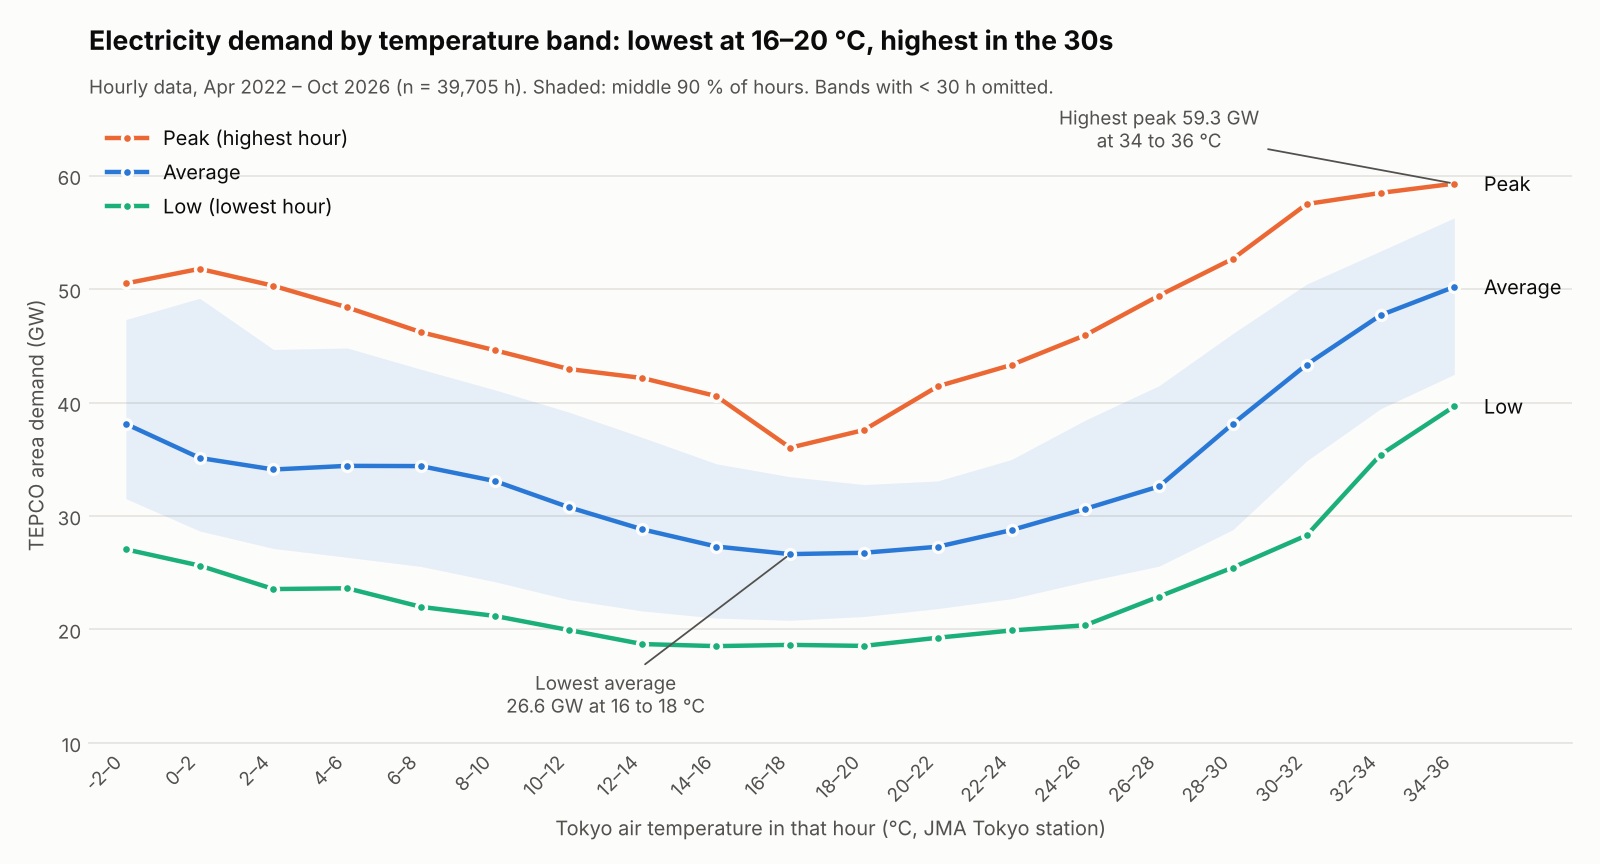

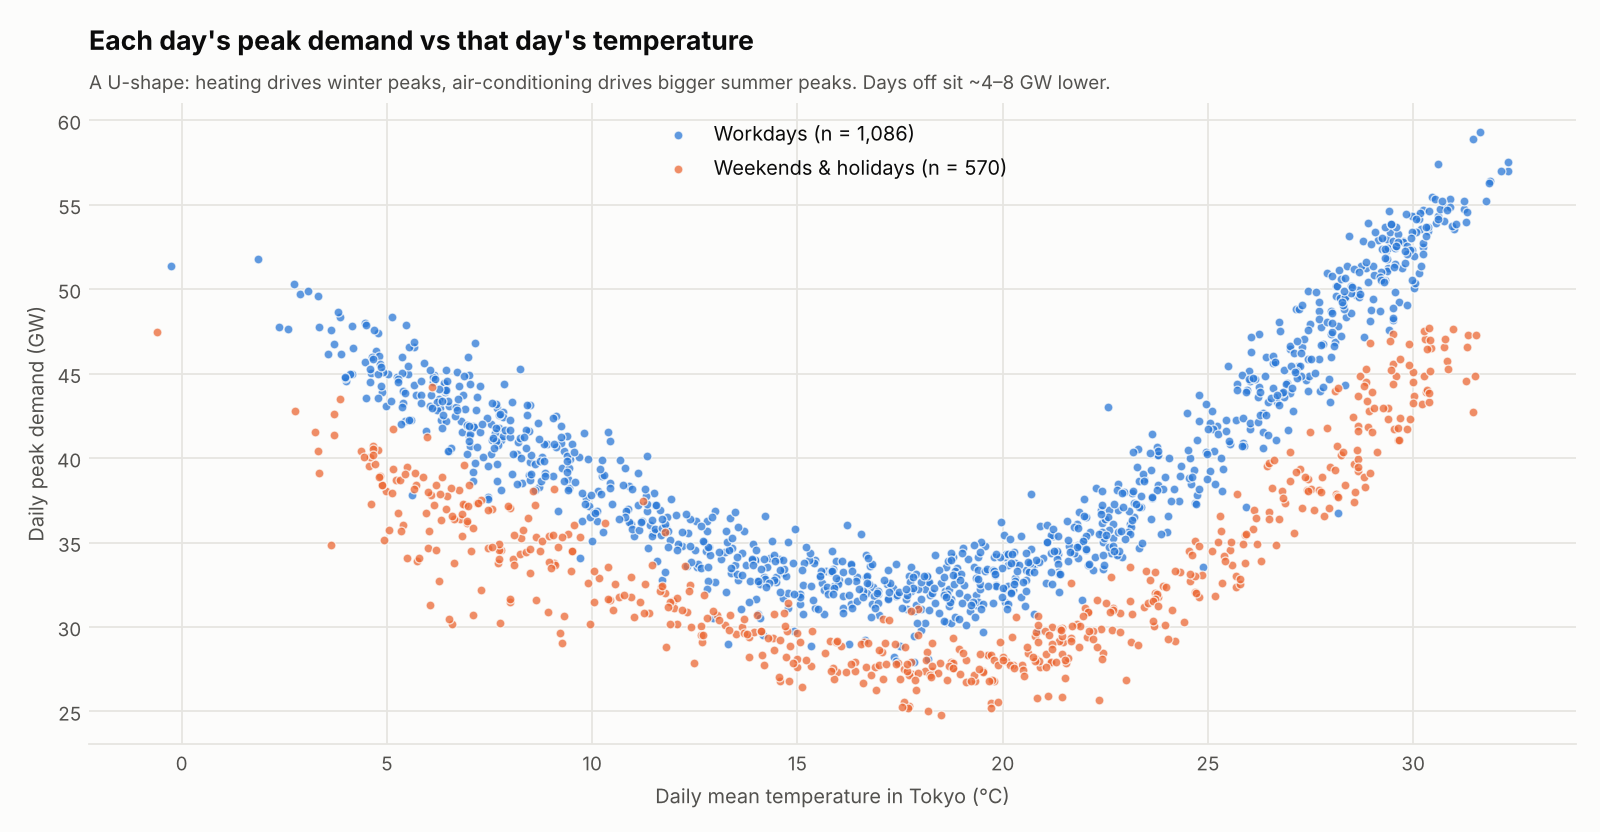

{'lowest_mean_demand_band': '16 to 18',
 'lowest_mean_demand_gw': 26.64,
 'highest_mean_demand_band': '34 to 36',
 'highest_mean_demand_gw': 50.2,
 'highest_peak_band': '34 to 36',
 'highest_peak_gw': 59.3,
 'coldest_band_mean_gw': 38.12,
 'coldest_band': '-2 to 0',
 'winter_peak_band': '0 to 2',
 'winter_peak_gw': 51.79,
 'record_hour': '2022-08-02 13:00:00+09:00',
 'record_gw': 59.3,
 'record_temp_c': 34.9,
 'lowest_hour': '2025-05-04 06:00:00+09:00',
 'lowest_gw': 18.53,
 'lowest_temp_c': 15.9,
 'daily_lowest_band': '16 to 18',
 'summer_vs_mild_peak_ratio': 1.88}

In [14]:
from IPython.display import Image, display
display(Image(ROOT / "reports/figures/demand_by_temperature_band.png", width=820))
display(Image(ROOT / "reports/figures/daily_peak_vs_temperature.png", width=820))
keys

## 10. Verify the exported files

In [15]:
pq = pd.read_parquet(ROOT / "data/clean/tokyo_hourly_clean.parquet")
assert pq.shape == clean.shape and (pq.dtypes.astype(str) == clean.dtypes.astype(str)).all()
assert pq.index.is_unique and pq.index.is_monotonic_increasing
assert (pq.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all()
assert pq[["demand_gw", "temp_tokyo_c", "temp_band"]].notna().all().all()
assert pq.demand_gw.between(10, 70).all() and pq.temp_tokyo_c.between(-20, 45).all()
csv = pd.read_csv(ROOT / "data/clean/tokyo_hourly_clean.csv", index_col=0)
assert len(csv) == len(pq)
print(f"All checks passed: {len(pq):,} hourly rows, {pq.shape[1]} columns, continuous timeline, no missing demand/temperature.")

All checks passed: 39,744 hourly rows, 45 columns, continuous timeline, no missing demand/temperature.


## Summary
* **Loaded** 39,744 hourly records: TEPCO demand plus JMA weather from 8 stations.
* **Missing values:** checked blanks *and* gaps in the timeline. Short gaps (≤ 3 h) were interpolated and flagged; multi-day humidity outages were left blank on purpose. Demand and Tokyo temperature are complete.
* **Duplicates:** none found (row-level and timestamp-level checks kept in the pipeline).
* **Incorrect / inconsistent values:** range and consistency checks passed. 8 hours where TEPCO's two demand series disagree are flagged; 2 sharp temperature drops were confirmed as real storms and kept.
* **Types & units:** text timestamps → timezone-aware datetime (Asia/Tokyo); 万kW → GW; float32 measurements; bool flags; ordered categories for season, weekday, and temperature band.
* **Prepared for analysis:** Japanese holidays, workday flag, hour, season, 2 °C temperature bands, and a daily peak/low table.
* **Finding:** demand is lowest at **16–20 °C** and peaks in the **34–36 °C** band (59.3 GW), about 1.9× the mild-weather average. Cold weather raises demand too, but less than summer heat.